# Customer Churn & Retention Analysis

### IBM Telco Customer Dataset | Python Portfolio Project

**Project Type:** Exploratory Data Analysis (EDA)

**Tools:** Python, Pandas, Seaborn, Matplotlib, Google Colab

**Business Objective:** Identify customer groups associated with higher churn and develop evidence-based retention recommendations.

**Dataset:** IBM Telco Customer Churn — 7,043 customer records.

---

## 1. Data Loading and Exploration


In [18]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [19]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display the names of all columns
print("\nColumn names:")
print(df.columns.tolist())

# Check the types of data and missing values
print("\nDataset information:")
df.info()


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

In [20]:
# Convert TotalCharges from text to numbers
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Check for duplicate customer records
print("\nDuplicate customer IDs:")
print(df["customerID"].duplicated().sum())

# Check the updated data type
print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)


Missing values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Duplicate customer IDs:
0

TotalCharges data type:
float64


In [21]:
# Examine customers with missing TotalCharges
missing_customers = df[df["TotalCharges"].isnull()]

# Show their tenure and monthly charges
print(missing_customers[["tenure", "MonthlyCharges", "TotalCharges"]])

# Check whether all missing values belong to new customers
print("\nTenure values for these customers:")
print(missing_customers["tenure"].unique())


      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN

Tenure values for these customers:
[0]


In [22]:
# Replace missing TotalCharges with zero
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Check that no missing values remain
print("Total missing values:", df.isnull().sum().sum())

# Confirm the number of customers
print("Total customers:", len(df))

# Check the number of customers who churned
print("\nCustomer churn counts:")
print(df["Churn"].value_counts())

# Calculate the overall churn rate
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"\nOverall churn rate: {churn_rate:.2f}%")

Total missing values: 0
Total customers: 7043

Customer churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Overall churn rate: 26.54%


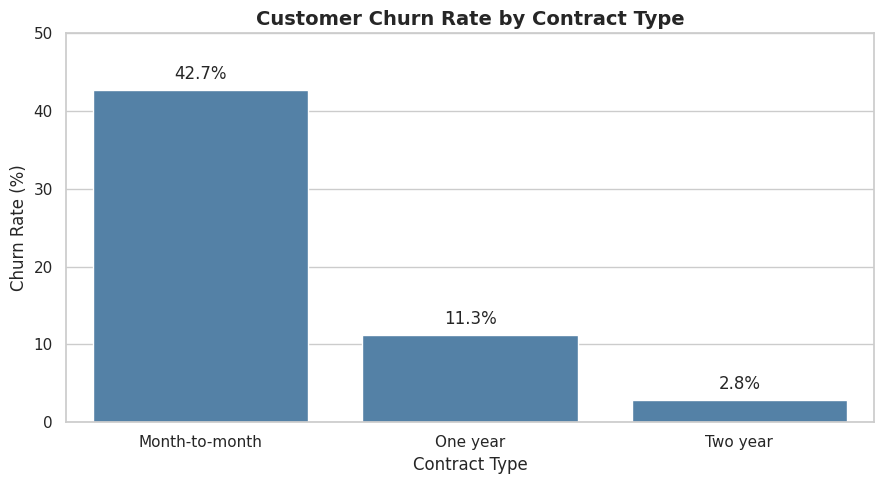

         Contract  Churn Rate
0  Month-to-month   42.709677
1        One year   11.269518
2        Two year    2.831858


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate churn percentage for each contract type
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate")
)

# Set the chart's appearance
sns.set_theme(style="whitegrid")

plt.figure(figsize=(9, 5))

# Create the bar chart
ax = sns.barplot(
    data=contract_churn,
    x="Contract",
    y="Churn Rate",
    color="steelblue"
)

# Add percentage labels above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

# Add professional chart labels
plt.title("Customer Churn Rate by Contract Type", fontsize=14, weight="bold")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

plt.tight_layout()
plt.show()

# Display exact percentages
print(contract_churn)

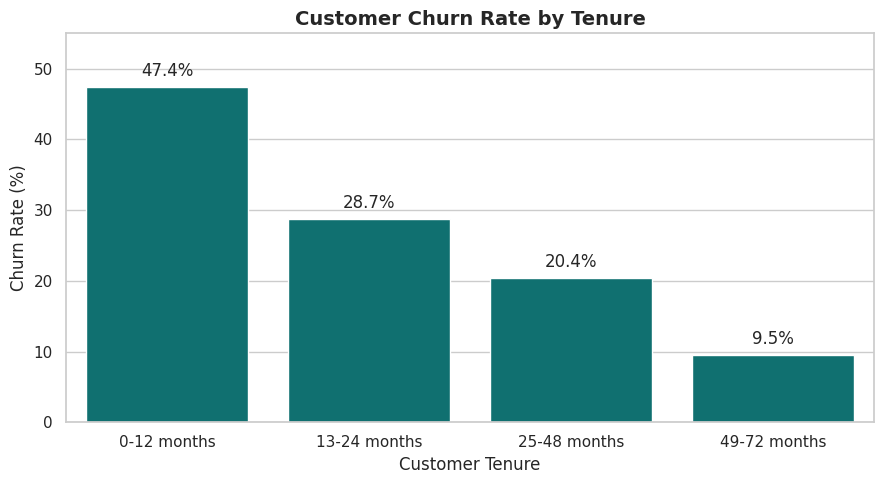

    TenureGroup  Churn Rate
0   0-12 months   47.438243
1  13-24 months   28.710938
2  25-48 months   20.388959
3  49-72 months    9.513176


In [24]:

# Group customers by how long they have stayed
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
)

# Calculate churn percentage for each group
tenure_churn = (
    df.groupby("TenureGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate")
)

# Create the chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=tenure_churn,
    x="TenureGroup",
    y="Churn Rate",
    color="teal"
)

# Add percentage labels
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

# Format the chart
plt.title("Customer Churn Rate by Tenure", fontsize=14, weight="bold")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 55)

plt.tight_layout()
plt.show()

# Display the exact results
print(tenure_churn)

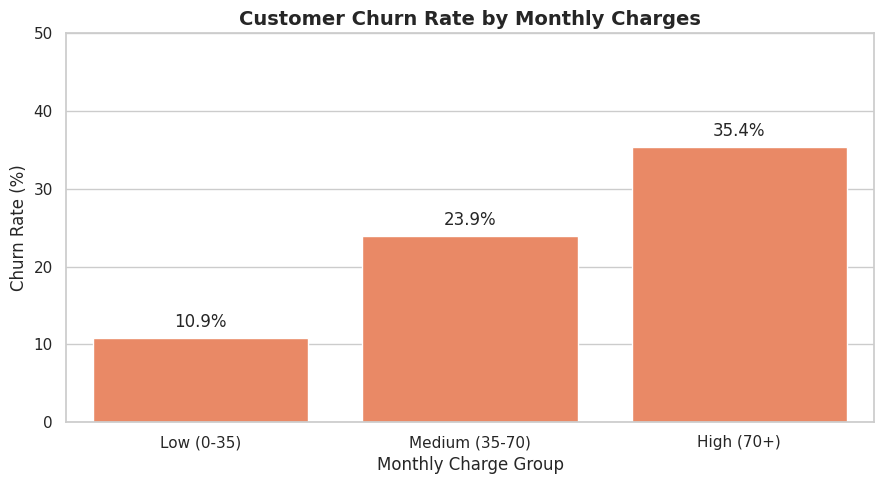

      ChargeGroup  Churn Rate
0      Low (0-35)   10.893372
1  Medium (35-70)   23.942029
2      High (70+)   35.361429


In [25]:
# Create monthly charge groups
df["ChargeGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 70, 120],
    labels=["Low (0-35)", "Medium (35-70)", "High (70+)"]
)

# Calculate churn rate for each price group
charge_churn = (
    df.groupby("ChargeGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate")
)

# Create the chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=charge_churn,
    x="ChargeGroup",
    y="Churn Rate",
    color="coral"
)

# Add percentage labels above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

# Format the chart
plt.title("Customer Churn Rate by Monthly Charges", fontsize=14, weight="bold")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

plt.tight_layout()
plt.show()

# Display the results
print(charge_churn)


Business Insights & Retention Recommendations

Executive Summary

This project analysed 7,043 telecommunications customer records to identify patterns associated with customer churn.

The overall customer churn rate was 26.54%, representing 1,869 customers who left the company.

Three important patterns emerged relating to contract type, customer tenure and monthly charges.

Recommendation 1: Encourage Longer-Term Contracts

Finding: Month-to-month customers had a churn rate of 42.7%, compared with just 2.8% for customers on two-year contracts.

Recommendation: Investigate incentives for month-to-month customers to move to longer-term contracts, such as loyalty discounts, additional services or flexible upgrade options.

Business value: Improving retention among month-to-month customers could reduce customer turnover and protect recurring revenue.

Recommendation 2: Improve First-Year Customer Retention

Finding: Customers with 0–12 months of tenure had a churn rate of 47.4%, compared with 9.5% among customers with 49–72 months of tenure.

Recommendation: Introduce a structured customer onboarding programme, including welcome communications, proactive support and satisfaction check-ins during the first year.

Business value: Improving the early customer experience could reduce customer losses and increase customer lifetime value.

Recommendation 3: Investigate Pricing and Perceived Value

Finding: Customers in the highest monthly charge group had a churn rate of 35.4%, compared with 10.9% in the lowest group.

Recommendation: Review the value offered to higher-paying customers, investigate satisfaction levels and test targeted retention offers.

Business value: Addressing potential value-for-money concerns could help retain customers who contribute substantial monthly revenue.

Limitations

These findings show associations rather than cause-and-effect relationships. Contract type, tenure and monthly charges may also be related to other customer characteristics.

The dataset is observational, so the recommendations should be tested before company-wide implementation.

Conclusion

The analysis highlights three potential priorities for customer retention: contract flexibility, early customer engagement and perceived service value.

These findings provide a foundation for further investigation and targeted retention strategies.

In [26]:
# Create a customer tenure category
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12 months", "13–24 months",
            "25–48 months", "49–72 months"]
)

# Calculate churn rate and customer count
# for each combination of contract and tenure
segment_analysis = (
    df.groupby(["Contract", "TenureGroup"], observed=True)
    .agg(
        Customers=("Churn", "count"),
        Churned=("Churn", lambda x: (x == "Yes").sum()),
        ChurnRate=("Churn", lambda x: (x == "Yes").mean() * 100)
    )
    .reset_index()
)

# Display the segments with the highest churn rates
segment_analysis.sort_values(
    "ChurnRate", ascending=False
).round(2)

,Contract,TenureGroup,Customers,Churned,ChurnRate
0,Month-to-month,0–12 months,1994,1024,51.35
1,Month-to-month,13–24 months,737,278,37.72
2,Month-to-month,25–48 months,802,264,32.92
3,Month-to-month,49–72 months,342,89,26.02
7,One year,49–72 months,634,82,12.93
6,One year,25–48 months,518,55,10.62
4,One year,0–12 months,124,13,10.48
5,One year,13–24 months,197,16,8.12
11,Two year,49–72 months,1263,42,3.33
10,Two year,25–48 months,274,6,2.19


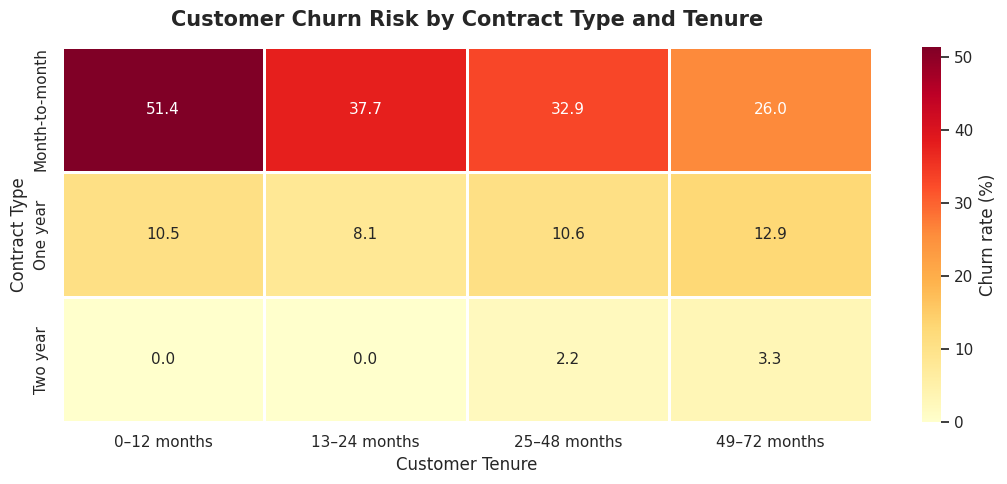

In [27]:
# Create a table of churn rates for the heatmap
heatmap_data = segment_analysis.pivot(
    index="Contract",
    columns="TenureGroup",
    values="ChurnRate"
)

# Arrange contract types in a meaningful order
heatmap_data = heatmap_data.reindex(
    ["Month-to-month", "One year", "Two year"]
)

# Create the heatmap
plt.figure(figsize=(11, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=1,
    cbar_kws={"label": "Churn rate (%)"},
    annot_kws={"size": 11}
)

plt.title(
    "Customer Churn Risk by Contract Type and Tenure",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Customer Tenure")
plt.ylabel("Contract Type")
plt.tight_layout()
plt.show()

In [28]:
# Identify customers who churned
churned_customers = df[df["Churn"] == "Yes"].copy()

# Calculate the total monthly charges of churned customers
total_revenue_exposure = churned_customers["MonthlyCharges"].sum()

# Calculate revenue exposure by contract and tenure
revenue_segments = (
    churned_customers
    .groupby(["Contract", "TenureGroup"], observed=True)
    .agg(
        ChurnedCustomers=("customerID", "count"),
        MonthlyRevenueExposure=("MonthlyCharges", "sum")
    )
    .reset_index()
)

# Show the segments with the largest revenue exposure
print(
    f"Total monthly revenue exposure: "
    f"{total_revenue_exposure:,.2f} currency units"
)

display(
    revenue_segments.sort_values(
        "MonthlyRevenueExposure", ascending=False
    ).round(2)
)

Total monthly revenue exposure: 139,130.85 currency units


,Contract,TenureGroup,ChurnedCustomers,MonthlyRevenueExposure
0,Month-to-month,0–12 months,1024,68301.45
2,Month-to-month,25–48 months,264,22557.00
1,Month-to-month,13–24 months,278,21980.30
3,Month-to-month,49–72 months,89,8008.35
7,One year,49–72 months,82,7842.95
6,One year,25–48 months,55,4521.35
9,Two year,49–72 months,42,3781.15
5,One year,13–24 months,16,1101.35
4,One year,0–12 months,13,652.80
8,Two year,25–48 months,6,384.15


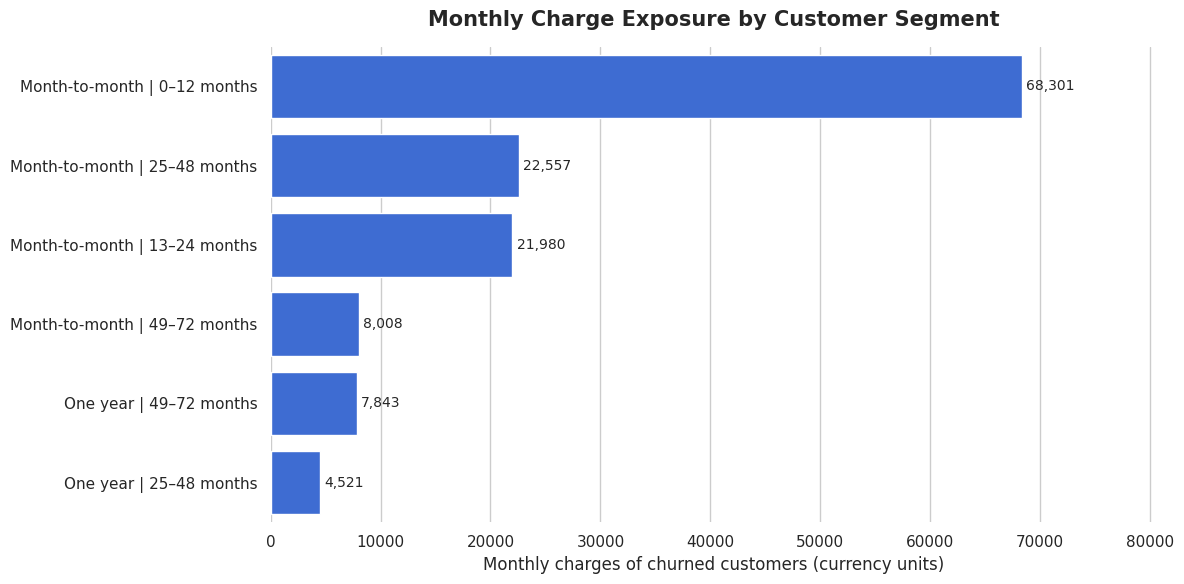

In [29]:
# Select the six segments with the highest exposure
top_segments = (
    revenue_segments
    .sort_values("MonthlyRevenueExposure", ascending=False)
    .head(6)
    .copy()
)

# Create readable labels
top_segments["Segment"] = (
    top_segments["Contract"]
    + " | "
    + top_segments["TenureGroup"].astype(str)
)

# Create a horizontal bar chart
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_segments,
    x="MonthlyRevenueExposure",
    y="Segment",
    color="#2563EB"
)

# Add values to the end of each bar
for bar in ax.patches:
    value = bar.get_width()
    ax.text(
        value + 400,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}",
        va="center",
        fontsize=10
    )

plt.title(
    "Monthly Charge Exposure by Customer Segment",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Monthly charges of churned customers (currency units)")
plt.ylabel("")
plt.xlim(0, top_segments["MonthlyRevenueExposure"].max() * 1.18)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

In [30]:
# Monthly charge exposure in our priority segment
priority_exposure = 68301.45

# Hypothetical percentages of churn prevented
retention_scenarios = [0.05, 0.10, 0.15, 0.20]

# Calculate potential monthly charges retained
scenario_results = pd.DataFrame({
    "Churn Prevented": ["5%", "10%", "15%", "20%"],
    "Potential Monthly Charges Retained": [
        priority_exposure * rate
        for rate in retention_scenarios
    ]
})

display(scenario_results.round(2))

,Churn Prevented,Potential Monthly Charges Retained
0,5%,3415.07
1,10%,6830.14
2,15%,10245.22
3,20%,13660.29


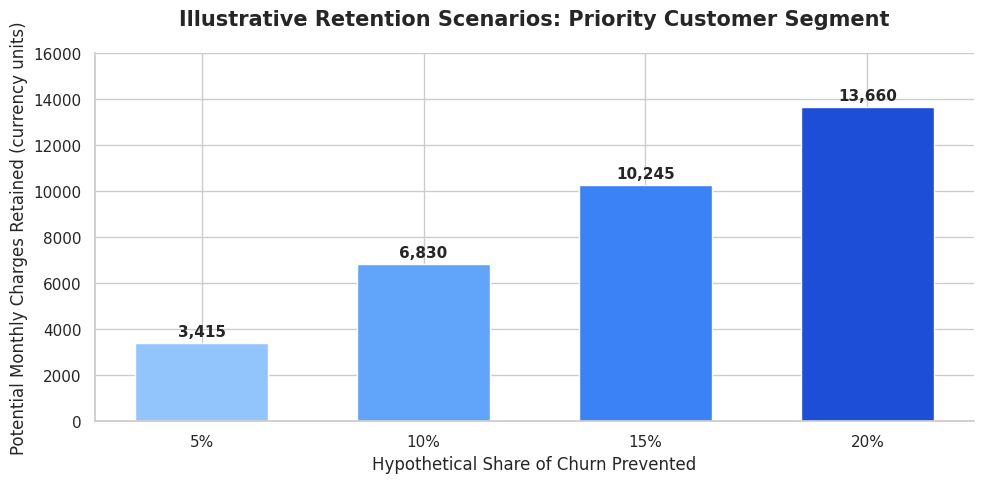

In [31]:
# Create the scenario chart
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    scenario_results["Churn Prevented"],
    scenario_results["Potential Monthly Charges Retained"],
    color=["#93C5FD", "#60A5FA", "#3B82F6", "#1D4ED8"],
    width=0.6
)

# Display the value above each bar
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 300,
        f"{height:,.0f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Illustrative Retention Scenarios: Priority Customer Segment",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Hypothetical Share of Churn Prevented")
ax.set_ylabel("Potential Monthly Charges Retained (currency units)")

ax.set_ylim(0, 16000)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

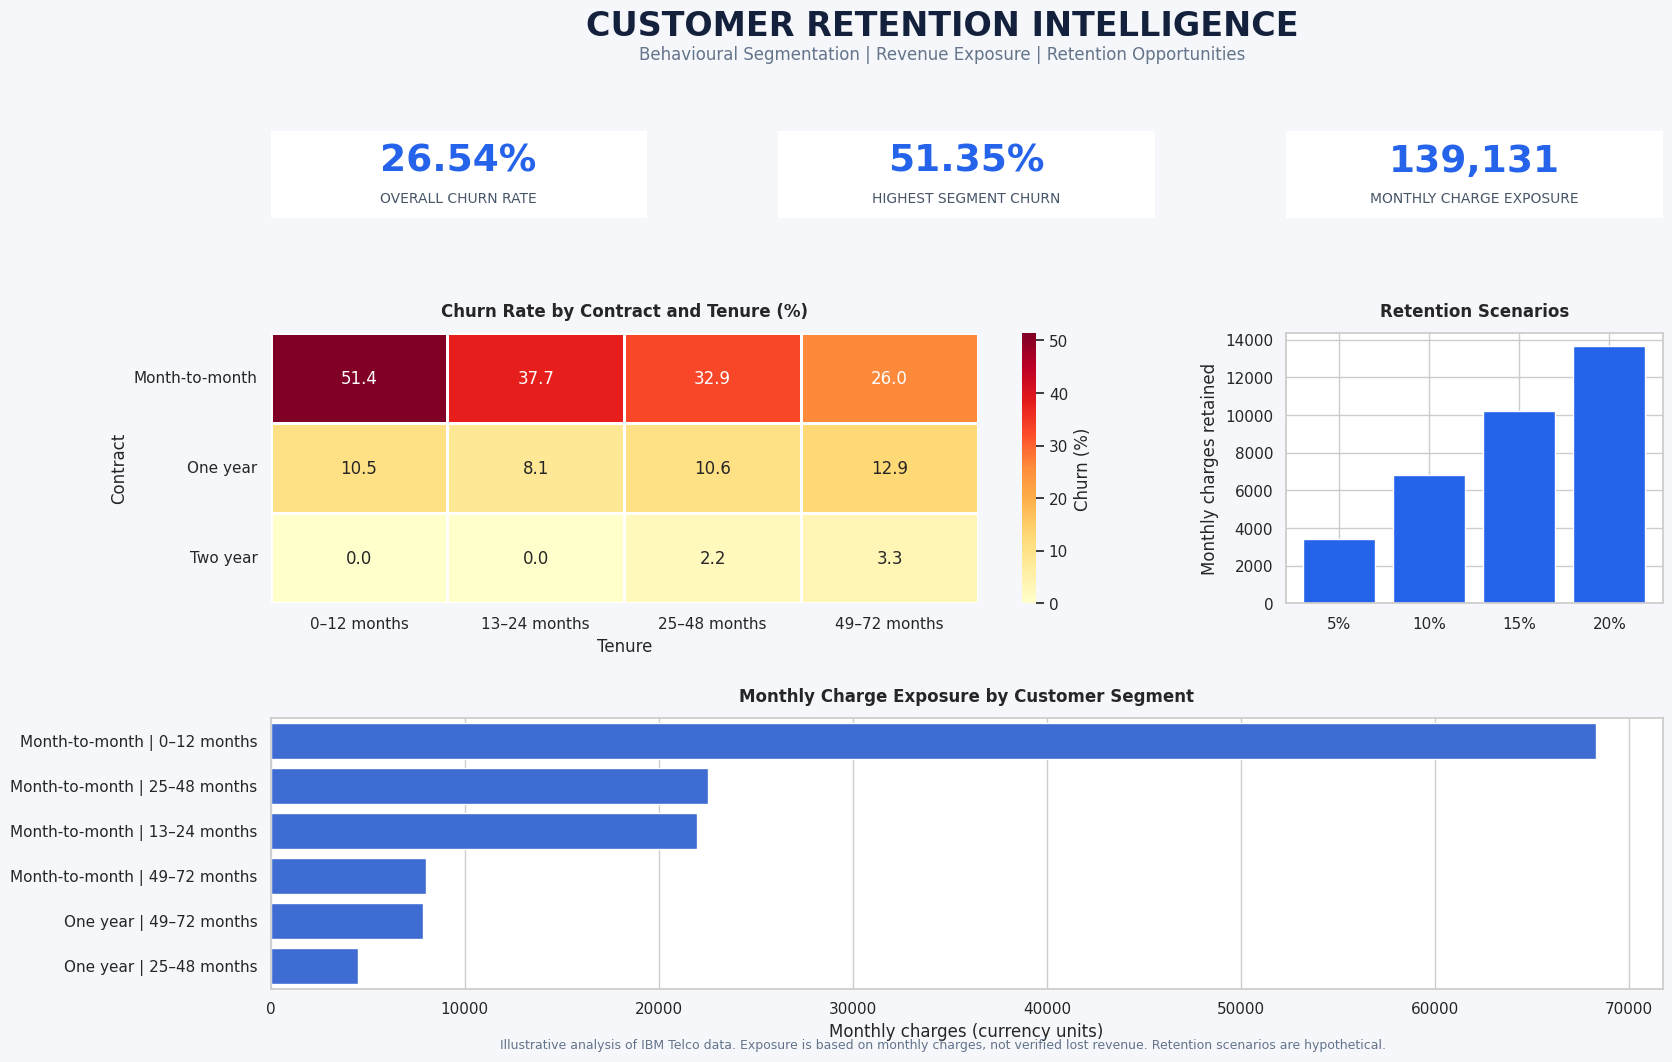

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent professional appearance
sns.set_theme(style="whitegrid")

fig = plt.figure(figsize=(16, 11), facecolor="#F5F7FB")

fig.suptitle(
    "CUSTOMER RETENTION INTELLIGENCE",
    fontsize=24,
    fontweight="bold",
    color="#14213D",
    y=0.97
)

fig.text(
    0.5, 0.925,
    "Behavioural Segmentation | Revenue Exposure | Retention Opportunities",
    ha="center",
    fontsize=12,
    color="#64748B"
)

# Create the dashboard layout
gs = fig.add_gridspec(
    3, 3,
    height_ratios=[0.65, 2, 2],
    hspace=0.55,
    wspace=0.35,
    left=0.08,
    right=0.95,
    top=0.86,
    bottom=0.08
)

# KPI cards
kpis = [
    ("OVERALL CHURN RATE", "26.54%"),
    ("HIGHEST SEGMENT CHURN", "51.35%"),
    ("MONTHLY CHARGE EXPOSURE", "139,131")
]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.set_facecolor("white")

    ax.text(
        0.5, 0.65, value,
        ha="center", va="center",
        fontsize=27, fontweight="bold",
        color="#2563EB",
        transform=ax.transAxes
    )

    ax.text(
        0.5, 0.22, label,
        ha="center", va="center",
        fontsize=10, color="#475569",
        transform=ax.transAxes
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

# Chart 1: Churn heatmap
ax1 = fig.add_subplot(gs[1, :2])

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=1,
    cbar_kws={"label": "Churn (%)"},
    ax=ax1
)

ax1.set_title(
    "Churn Rate by Contract and Tenure (%)",
    fontweight="bold",
    pad=12
)

ax1.set_xlabel("Tenure")
ax1.set_ylabel("Contract")

# Chart 2: Retention scenarios
ax2 = fig.add_subplot(gs[1, 2])

ax2.bar(
    scenario_results["Churn Prevented"],
    scenario_results["Potential Monthly Charges Retained"],
    color="#2563EB"
)

ax2.set_title(
    "Retention Scenarios",
    fontweight="bold",
    pad=12
)

ax2.set_ylabel("Monthly charges retained")
ax2.tick_params(axis="x", rotation=0)

# Chart 3: Revenue exposure
ax3 = fig.add_subplot(gs[2, :])

sns.barplot(
    data=top_segments,
    x="MonthlyRevenueExposure",
    y="Segment",
    color="#2563EB",
    ax=ax3
)

ax3.set_title(
    "Monthly Charge Exposure by Customer Segment",
    fontweight="bold",
    pad=12
)

ax3.set_xlabel("Monthly charges (currency units)")
ax3.set_ylabel("")

# Explain the limitations
fig.text(
    0.5, 0.025,
    "Illustrative analysis of IBM Telco data. "
    "Exposure is based on monthly charges, not verified lost revenue. "
    "Retention scenarios are hypothetical.",
    ha="center",
    fontsize=9,
    color="#64748B"
)

plt.show()

In [34]:
# Import tools for machine learning
from sklearn.model_selection import train_test_split

# Define the variable we want to predict
y = df["Churn"].map({"No": 0, "Yes": 1})

# Select the customer information used for prediction
X = df.drop(
    columns=[
        "customerID",
        "Churn",
        "TenureGroup",
        "ChargeGroup"
    ],
    errors="ignore"
)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training customers: 5634
Testing customers: 1409
Training churn rate: 26.54 %
Testing churn rate: 26.54 %


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Prepare the different types of data
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Build the complete machine learning pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

# Train the model using training data only
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Logistic Regression model trained successfully!
Numerical features: 4
Categorical features: 15


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Predict churn for customers the model has not trained on
y_pred = logistic_model.predict(X_test)

# Calculate the predicted probability of churn
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate model performance
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ]
})

display(results.round(3))

# Display the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

,Metric,Score
0,Accuracy,0.806
1,Precision,0.657
2,Recall,0.559
3,F1 Score,0.604
4,ROC-AUC,0.842


Confusion Matrix:
[[926 109]
 [165 209]]


In [37]:
from sklearn.ensemble import RandomForestClassifier

# Build the Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train using the training data only
random_forest_model.fit(X_train, y_train)

# Predict on the test data
rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
rf_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred),
        recall_score(y_test, rf_pred),
        f1_score(y_test, rf_pred),
        roc_auc_score(y_test, rf_prob)
    ]
})

display(rf_results.round(3))

print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

,Metric,Score
0,Accuracy,0.804
1,Precision,0.673
2,Recall,0.511
3,F1 Score,0.581
4,ROC-AUC,0.841


Random Forest Confusion Matrix:
[[942  93]
 [183 191]]


In [38]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Create five stratified validation folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Models to compare
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

# Evaluate models using training data only
cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "ROC-AUC": "roc_auc",
            "Recall": "recall",
            "F1": "f1"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean ROC-AUC": scores["test_ROC-AUC"].mean(),
        "ROC-AUC Std": scores["test_ROC-AUC"].std(),
        "Mean Recall": scores["test_Recall"].mean(),
        "Mean F1": scores["test_F1"].mean()
    })

cv_comparison = pd.DataFrame(cv_results)

display(cv_comparison.round(3))

,Model,Mean ROC-AUC,ROC-AUC Std,Mean Recall,Mean F1
0,Logistic Regression,0.846,0.013,0.543,0.592
1,Random Forest,0.844,0.010,0.503,0.576


In [39]:
from sklearn.inspection import permutation_importance

# Measure feature importance on the training data
importance = permutation_importance(
    logistic_model,
    X_train,
    y_train,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Organise results into a table
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

# Display the 10 most important features
top_features = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .head(10)
)

display(top_features.round(4))

,Feature,Importance,Std
4,tenure,0.1695,0.0032
7,InternetService,0.0495,0.0037
14,Contract,0.0354,0.0027
17,MonthlyCharges,0.0264,0.0025
18,TotalCharges,0.0208,0.0013
13,StreamingMovies,0.0056,0.0004
12,StreamingTV,0.0055,0.0014
8,OnlineSecurity,0.0048,0.0010
6,MultipleLines,0.0040,0.0003
16,PaymentMethod,0.0040,0.0006


In [40]:
from sklearn.inspection import permutation_importance

# Measure feature importance on the training data
importance = permutation_importance(
    logistic_model,
    X_train,
    y_train,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Organise results into a table
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

# Display the 10 most important features
top_features = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .head(10)
)

display(top_features.round(4))

,Feature,Importance,Std
4,tenure,0.1695,0.0032
7,InternetService,0.0495,0.0037
14,Contract,0.0354,0.0027
17,MonthlyCharges,0.0264,0.0025
18,TotalCharges,0.0208,0.0013
13,StreamingMovies,0.0056,0.0004
12,StreamingTV,0.0055,0.0014
8,OnlineSecurity,0.0048,0.0010
6,MultipleLines,0.0040,0.0003
16,PaymentMethod,0.0040,0.0006


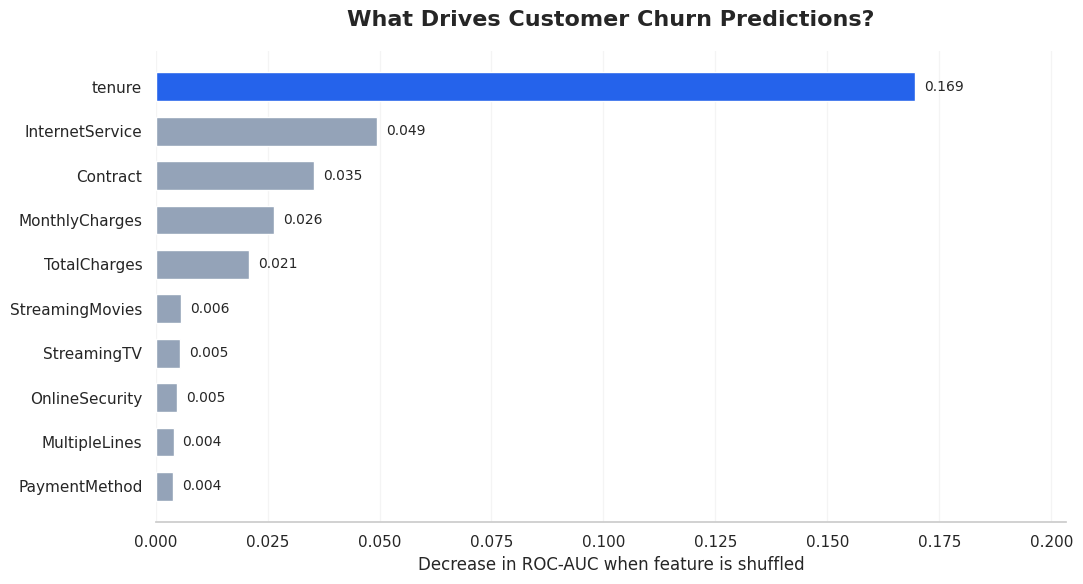

In [41]:
# Arrange features from lowest to highest importance
plot_data = top_features.sort_values("Importance")

fig, ax = plt.subplots(figsize=(11, 6))

# Highlight the most important feature
colors = [
    "#2563EB" if feature == "tenure" else "#94A3B8"
    for feature in plot_data["Feature"]
]

# Create horizontal bars
ax.barh(
    plot_data["Feature"],
    plot_data["Importance"],
    color=colors,
    height=0.65
)

# Add importance values beside each bar
for i, value in enumerate(plot_data["Importance"]):
    ax.text(
        value + 0.002,
        i,
        f"{value:.3f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "What Drives Customer Churn Predictions?",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Decrease in ROC-AUC when feature is shuffled")
ax.set_ylabel("")

ax.set_xlim(0, plot_data["Importance"].max() * 1.2)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

In [42]:
# Compare different churn probability thresholds
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60]

threshold_results = []

for threshold in thresholds:

    # Convert probabilities into churn predictions
    predictions = (y_prob >= threshold).astype(int)

    # Calculate performance at each threshold
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions
        ),
        "F1 Score": f1_score(
            y_test, predictions
        ),
        "Customers Flagged": predictions.sum()
    })

# Display the comparison
threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison.round(3))

,Threshold,Precision,Recall,F1 Score,Customers Flagged
0,0.2,0.467,0.856,0.604,685
1,0.3,0.519,0.754,0.615,543
2,0.4,0.568,0.668,0.614,440
3,0.5,0.657,0.559,0.604,318
4,0.6,0.718,0.401,0.515,209


In [43]:
from sklearn.model_selection import cross_val_predict

# Generate out-of-fold predictions using training data only
cv_probabilities = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Evaluate candidate thresholds on training predictions
threshold_cv_results = []

for threshold in [0.20, 0.30, 0.40, 0.50, 0.60]:

    predictions = (
        cv_probabilities >= threshold
    ).astype(int)

    threshold_cv_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions
        ),
        "F1 Score": f1_score(
            y_train, predictions
        ),
        "Customers Flagged": predictions.sum()
    })

cv_threshold_table = pd.DataFrame(threshold_cv_results)

display(cv_threshold_table.round(3))

,Threshold,Precision,Recall,F1 Score,Customers Flagged
0,0.2,0.475,0.854,0.611,2688
1,0.3,0.541,0.767,0.634,2120
2,0.4,0.594,0.664,0.627,1672
3,0.5,0.653,0.543,0.593,1244
4,0.6,0.711,0.397,0.509,834


In [44]:
# Threshold selected using training cross-validation
selected_threshold = 0.30

# Apply the threshold to test-set probabilities
final_predictions = (
    y_prob >= selected_threshold
).astype(int)

# Calculate performance
final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, final_predictions),
        precision_score(y_test, final_predictions),
        recall_score(y_test, final_predictions),
        f1_score(y_test, final_predictions),
        roc_auc_score(y_test, y_prob)
    ]
})

display(final_metrics.round(3))

print("Confusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

print("Customers flagged:", final_predictions.sum())

,Metric,Score
0,Accuracy,0.749
1,Precision,0.519
2,Recall,0.754
3,F1 Score,0.615
4,ROC-AUC,0.842


Confusion Matrix:
[[774 261]
 [ 92 282]]
Customers flagged: 543


In [45]:
# Create a table of test customers and their churn predictions
targeting_results = pd.DataFrame({
    "ActualChurn": y_test.to_numpy(),
    "ChurnProbability": y_prob,
    "MonthlyCharges": X_test["MonthlyCharges"].to_numpy()
})

# Rank customers by predicted churn probability
targeting_results = targeting_results.sort_values(
    "ChurnProbability",
    ascending=False
).reset_index(drop=True)

# Evaluate different outreach capacities
capacities = [50, 100, 200, 300, 500]

targeting_summary = []

for capacity in capacities:

    # Select the highest-risk customers
    selected = targeting_results.head(capacity)

    # Count actual churn cases in the selected group
    churners_identified = selected["ActualChurn"].sum()

    targeting_summary.append({
        "Customers Contacted": capacity,
        "Churners Identified": churners_identified,
        "Precision": churners_identified / capacity,
        "Share of All Churners": (
            churners_identified / y_test.sum()
        )
    })

targeting_table = pd.DataFrame(targeting_summary)

display(targeting_table.round(3))

,Customers Contacted,Churners Identified,Precision,Share of All Churners
0,50,39,0.780,0.104
1,100,74,0.740,0.198
2,200,145,0.725,0.388
3,300,198,0.660,0.529
4,500,269,0.538,0.719


In [46]:
# Overall churn rate in the test population
baseline_churn_rate = y_test.mean()

# Calculate lift compared with random targeting
targeting_table["Lift"] = (
    targeting_table["Precision"] / baseline_churn_rate
)

# Calculate expected churners from random targeting
targeting_table["Random Targeting Expected"] = (
    targeting_table["Customers Contacted"]
    * baseline_churn_rate
)

# Display the updated targeting comparison
display(targeting_table.round(2))

,Customers Contacted,Churners Identified,Precision,Share of All Churners,Lift,Random Targeting Expected
0,50,39,0.78,0.10,2.94,13.27
1,100,74,0.74,0.20,2.79,26.54
2,200,145,0.72,0.39,2.73,53.09
3,300,198,0.66,0.53,2.49,79.63
4,500,269,0.54,0.72,2.03,132.72


In [47]:
# Select the 100 highest-ranked customers
top_100 = targeting_results.head(100)

# Hypothetical campaign assumptions
cost_per_contact = 5
retention_success_rate = 0.10
additional_months_retained = 3

# Number of actual churners in the selected group
churners_identified = top_100["ActualChurn"].sum()

# Monthly charges associated with actual churners
churner_monthly_charges = top_100.loc[
    top_100["ActualChurn"] == 1,
    "MonthlyCharges"
].sum()

# Estimate the campaign's financial outcome
campaign_cost = len(top_100) * cost_per_contact

potential_revenue_retained = (
    churner_monthly_charges
    * retention_success_rate
    * additional_months_retained
)

estimated_net_value = (
    potential_revenue_retained - campaign_cost
)

# Display results
print("Customers contacted:", len(top_100))
print("Actual churners identified:", churners_identified)
print("Campaign cost:", round(campaign_cost, 2))
print(
    "Illustrative revenue retained:",
    round(potential_revenue_retained, 2)
)
print(
    "Illustrative net revenue after outreach cost:",
    round(estimated_net_value, 2)
)

Customers contacted: 100
Actual churners identified: 74
Campaign cost: 500
Illustrative revenue retained: 1838.79
Illustrative net revenue after outreach cost: 1338.79


In [48]:
# Test different hypothetical retention success rates
success_rates = [0.02, 0.05, 0.10, 0.15, 0.20]

sensitivity_results = []

for rate in success_rates:

    revenue_retained = (
        churner_monthly_charges
        * rate
        * additional_months_retained
    )

    net_value = revenue_retained - campaign_cost

    sensitivity_results.append({
        "Retention Success Rate": f"{rate:.0%}",
        "Potential Charges Retained": revenue_retained,
        "Outreach Cost": campaign_cost,
        "Illustrative Net Revenue": net_value
    })

sensitivity_table = pd.DataFrame(sensitivity_results)

display(sensitivity_table.round(2))

,Retention Success Rate,Potential Charges Retained,Outreach Cost,Illustrative Net Revenue
0,2%,367.76,500,-132.24
1,5%,919.40,500,419.40
2,10%,1838.79,500,1338.79
3,15%,2758.18,500,2258.18
4,20%,3677.58,500,3177.58


In [49]:
# Calculate the minimum retention success rate
# needed to cover outreach costs

break_even_rate = (
    campaign_cost
    / (
        churner_monthly_charges
        * additional_months_retained
    )
)

print(
    "Break-even retention success rate:",
    f"{break_even_rate:.2%}"
)

print(
    "Illustrative retained charges at break-even:",
    round(
        churner_monthly_charges
        * break_even_rate
        * additional_months_retained,
        2
    )
)

print(
    "Campaign outreach cost:",
    round(campaign_cost, 2)
)

Break-even retention success rate: 2.72%
Illustrative retained charges at break-even: 500.0
Campaign outreach cost: 500


Business Recommendations & Limitations

Executive Summary

This project analysed 7,043 telecommunications customer records to identify churn patterns, develop predictive models, and evaluate potential customer retention strategies.

The overall customer churn rate was 26.54%. Customers on month-to-month contracts with 0–12 months of tenure represented a particularly high-risk segment, with a 51.35% churn rate.

A Logistic Regression model achieved a ROC-AUC of 0.842 on the held-out test set. Using a decision threshold of 0.30, selected through training-set cross-validation, the model identified 75.4% of actual churn cases in the test data.

Key Findings

1. Customer tenure and contract type are important indicators of churn.

The highest-risk customer segment consisted of month-to-month subscribers in their first 12 months. This group contained 1,994 customers and accounted for approximately 54.8% of all observed churn cases.

2. Predictive modelling can support targeted retention efforts.

Among the 100 customers with the highest predicted churn probabilities in the test set, 74 had actually churned. This represents a 2.79× lift over the churn concentration expected from random customer selection.

3. The potential financial value depends on intervention effectiveness.

An illustrative campaign targeting these 100 customers, assuming a contact cost of 5 currency units per customer, a 10% churn-prevention rate and three additional months of retention, produced:

Potential retained customer charges: 1,838.79 currency units

Outreach cost: 500 currency units

Illustrative net revenue after outreach cost: 1,338.79 currency units

Revenue break-even retention success rate: 2.72%

These figures are scenario estimates rather than observed campaign outcomes.

Business Recommendations

Prioritise early-tenure, month-to-month customers. Investigate onboarding difficulties, service satisfaction and pricing concerns among this segment before designing targeted interventions.

Use predicted churn probabilities to guide outreach. A capacity-based ranking approach could help retention teams prioritise customers when resources are limited. Outreach capacity, customer value and intervention costs should inform the final targeting policy.

Pilot retention interventions before scaling. Conduct a controlled experiment comparing customers offered a retention intervention with a suitable control group. Measure incremental churn reduction, campaign costs and customer value rather than assuming that identified churners can be retained.

Monitor performance over time. Track recall, precision, targeting lift and model calibration as customer behaviour changes. Reassess the targeting strategy if performance deteriorates.

Limitations

Observational data: Relationships between customer characteristics and churn do not establish causation.

Historical snapshot: The dataset does not provide a complete longitudinal history, so the analysis cannot establish how predictions would perform in a live deployment.

Exploratory test-set analysis: The test set was examined during threshold exploration and targeting analysis. The reported results should not be treated as fully independent validation of the final strategy.

Unverified intervention effectiveness: The financial scenarios use hypothetical retention success rates and do not demonstrate actual churn prevention.

Simplified financial assumptions: Monthly charges are used as a revenue proxy. The scenarios exclude service delivery costs, incentives, contribution margins and other relevant expenses.

Model fairness: Performance across customer groups has not yet been assessed. Fairness and customer-impact checks would be necessary before operational deployment.

Conclusion

The analysis demonstrates how exploratory data analysis, customer segmentation, predictive modelling and scenario analysis can be combined to support a customer retention strategy.

The strongest practical opportunity is not simply predicting churn, but using risk estimates to prioritise limited retention resources and testing whether those interventions create measurable incremental value.

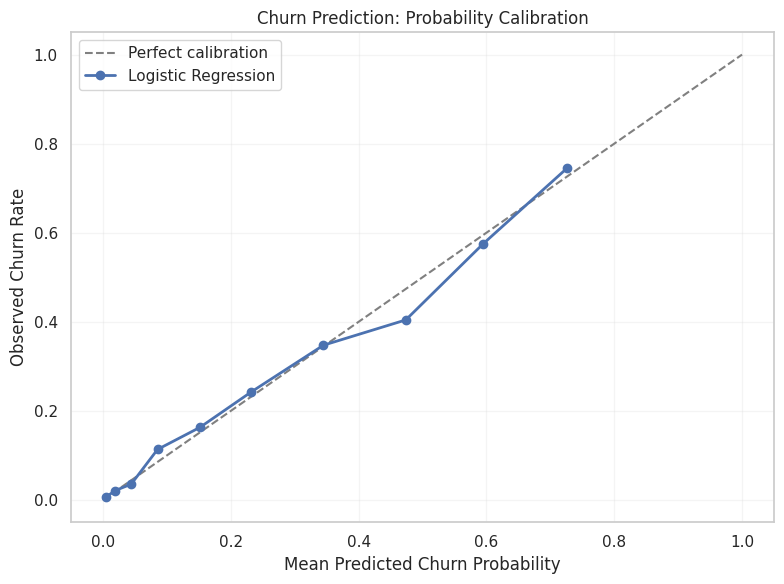

In [50]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Compare predicted probabilities with actual churn rates
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test,
    y_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

# Perfect calibration reference line
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="grey",
    label="Perfect calibration"
)

# Our model's calibration
plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    linewidth=2,
    label="Logistic Regression"
)

plt.xlabel("Mean Predicted Churn Probability")
plt.ylabel("Observed Churn Rate")
plt.title("Churn Prediction: Probability Calibration")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [51]:
from sklearn.metrics import brier_score_loss

# Calculate the model's probability error
model_brier = brier_score_loss(y_test, y_prob)

# Baseline: predict the training-set churn rate
# for every customer
baseline_probability = y_train.mean()

baseline_brier = brier_score_loss(
    y_test,
    [baseline_probability] * len(y_test)
)

print("Logistic Regression Brier Score:", round(model_brier, 4))
print("Baseline Brier Score:", round(baseline_brier, 4))

Logistic Regression Brier Score: 0.138
Baseline Brier Score: 0.195


In [52]:
%pip install -q shap

In [53]:
import shap

# Get the trained preprocessing and classification components
trained_preprocessor = logistic_model.named_steps["preprocessor"]
trained_classifier = logistic_model.named_steps["classifier"]

# Transform the training data into the format used by the model
X_train_transformed = trained_preprocessor.transform(X_train)

# Get the names of the transformed features
feature_names = trained_preprocessor.get_feature_names_out()

print("Original features:", X_train.shape[1])
print("Features after preprocessing:", len(feature_names))
print("Transformed training shape:", X_train_transformed.shape)

Original features: 19
Features after preprocessing: 45
Transformed training shape: (5634, 45)


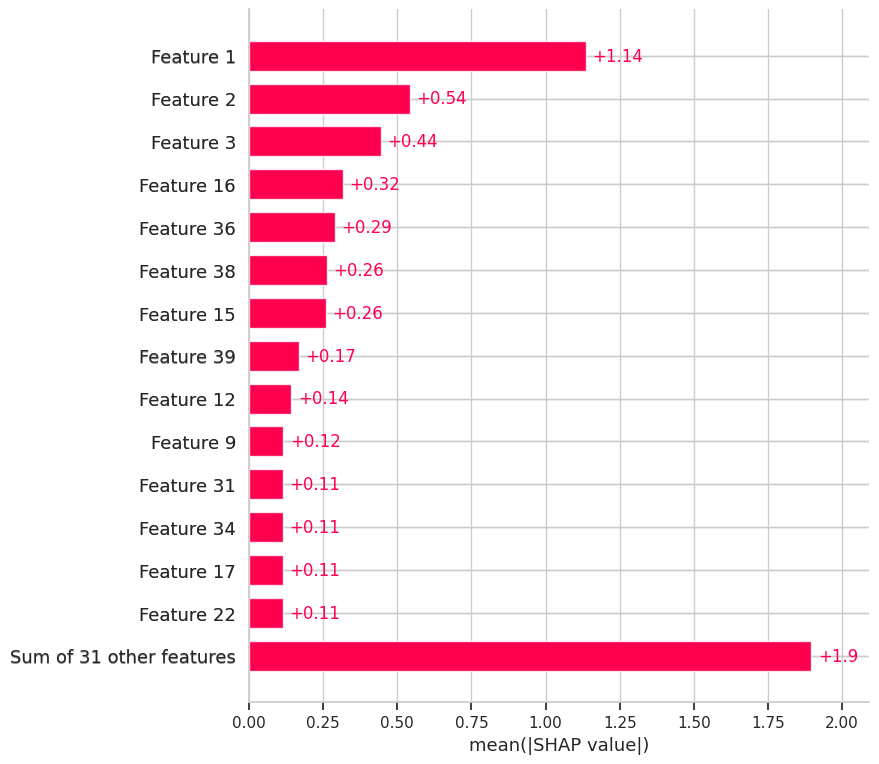

In [54]:
# Create a SHAP explainer for Logistic Regression
explainer = shap.LinearExplainer(
    trained_classifier,
    X_train_transformed
)

# Transform a sample of 300 test customers
X_test_sample = X_test.iloc[:300].copy()

X_test_transformed = trained_preprocessor.transform(
    X_test_sample
)

# Calculate SHAP values
shap_values = explainer(X_test_transformed)

# Display a SHAP feature importance chart
shap.plots.bar(
    shap_values,
    max_display=15
)

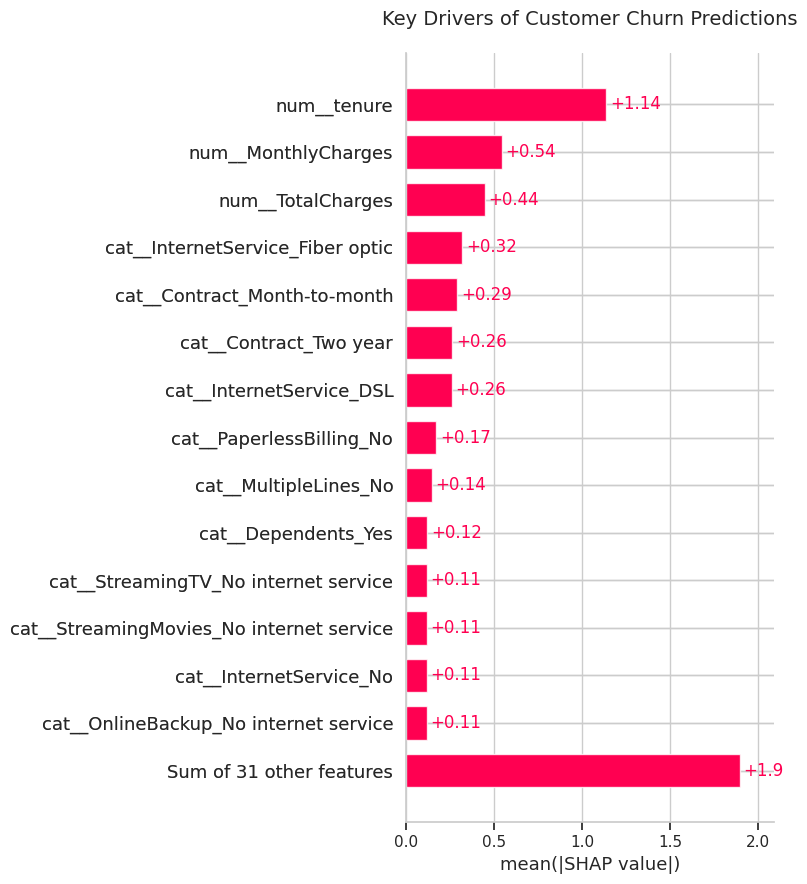

In [55]:
import numpy as np

# Give the SHAP explanation meaningful feature names
shap_values.feature_names = list(feature_names)

# Create a clearer feature importance chart
shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.title(
    "Key Drivers of Customer Churn Predictions",
    fontsize=14,
    pad=20
)

plt.tight_layout()
plt.show()

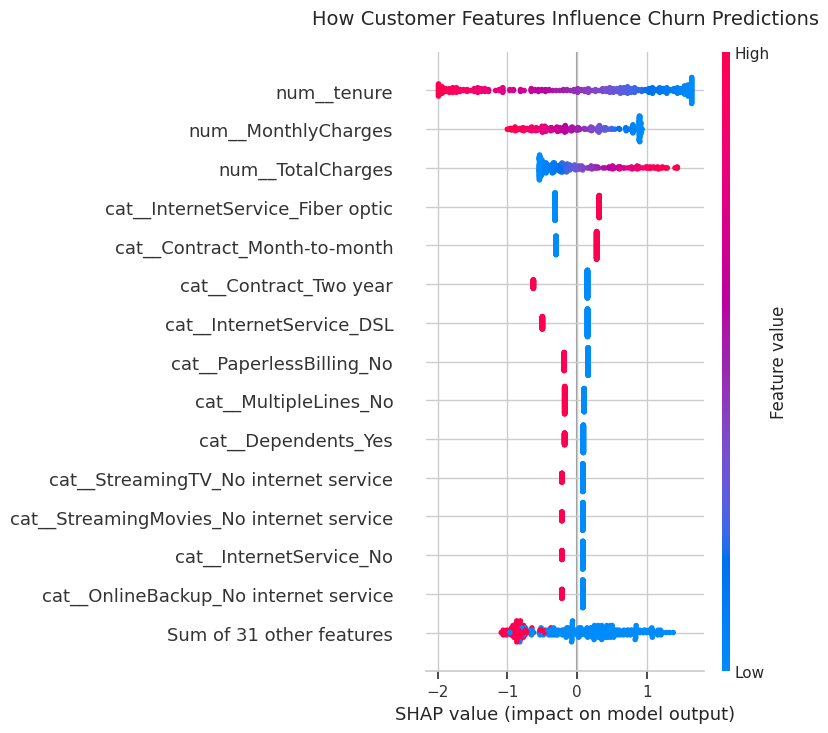

In [56]:
# Create a SHAP beeswarm plot
plt.figure(figsize=(11, 8))

shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title(
    "How Customer Features Influence Churn Predictions",
    fontsize=14,
    pad=20
)

plt.tight_layout()
plt.show()

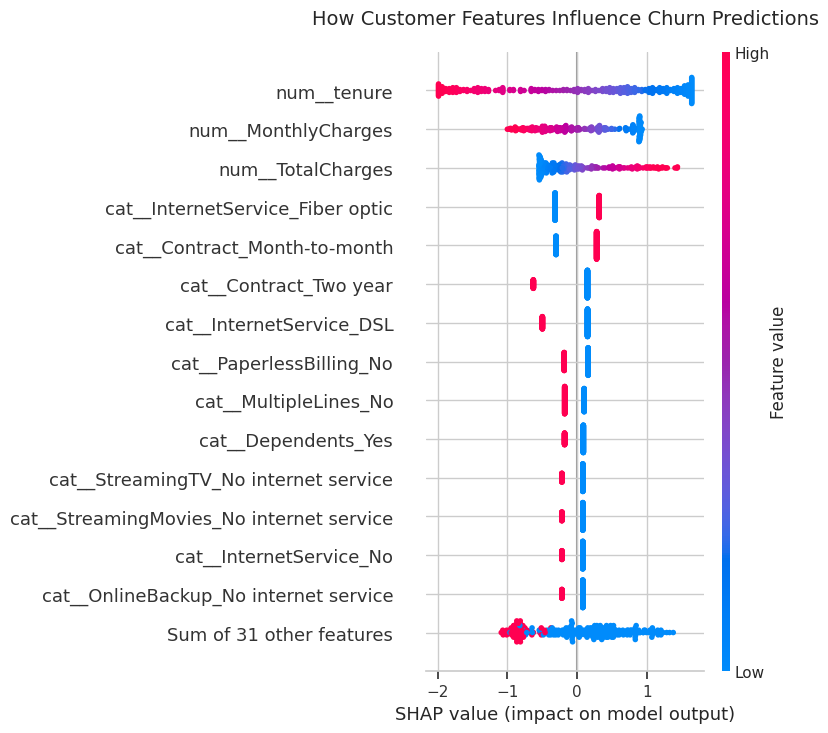

In [57]:
# Create a SHAP beeswarm plot
plt.figure(figsize=(11, 8))

shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title(
    "How Customer Features Influence Churn Predictions",
    fontsize=14,
    pad=20
)

plt.tight_layout()
plt.show()

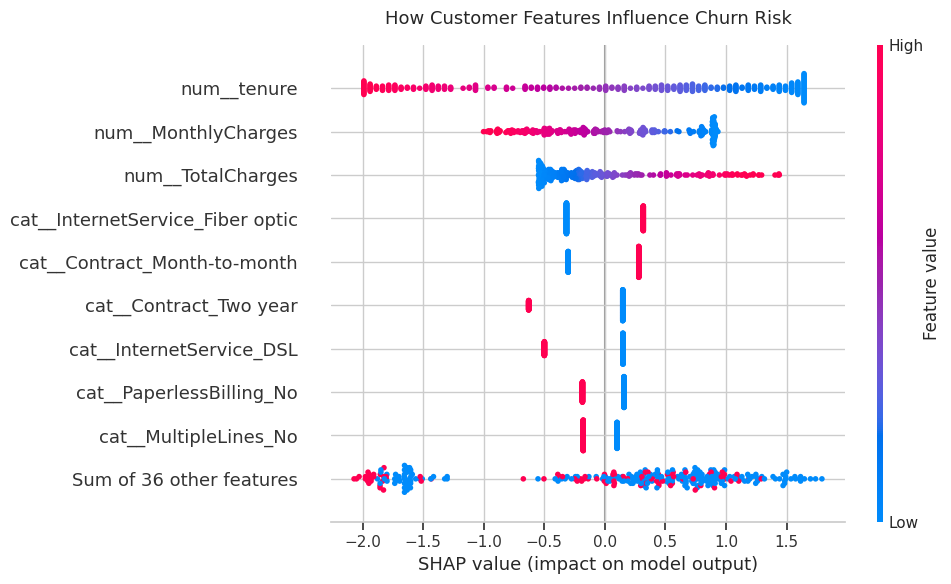

In [58]:
shap.plots.beeswarm(
    shap_values,
    max_display=10,
    plot_size=(10, 6),
    show=False
)

plt.title(
    "How Customer Features Influence Churn Risk",
    fontsize=13,
    pad=15
)

plt.tight_layout()
plt.show()

Predicted churn probability: 79.4%


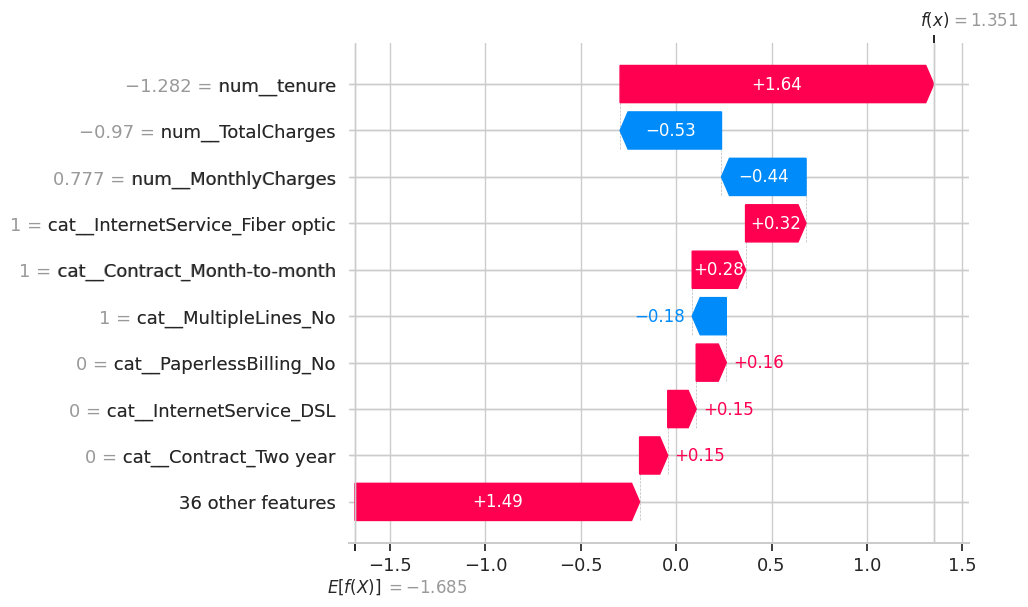

In [59]:
# Choose the customer with the highest predicted churn risk
customer_index = np.argmax(
    logistic_model.predict_proba(X_test_sample)[:, 1]
)

# Display their predicted churn probability
customer_probability = logistic_model.predict_proba(
    X_test_sample.iloc[[customer_index]]
)[0, 1]

print(
    "Predicted churn probability:",
    f"{customer_probability:.1%}"
)

# Explain the individual prediction
shap.plots.waterfall(
    shap_values[customer_index],
    max_display=10
)

Explainable AI: Individual Customer Prediction

SHAP was used to explain the Logistic Regression model's predictions at both the overall feature level and for an individual customer.

For one high-risk customer, the model predicted a 79.4% probability of churn.

The waterfall plot showed that shorter tenure was the strongest individual contributor increasing predicted churn risk. Fiber optic internet service and a month-to-month contract also increased the prediction, while other features partially offset these effects.

The SHAP contributions are expressed in log-odds rather than percentage points. These explanations describe how the fitted model uses customer characteristics and should not be interpreted as causal relationships.

Business implication: Individual explanations could help retention teams understand why customers receive high-risk scores and investigate appropriate interventions. However, SHAP values alone cannot determine which interventions would successfully prevent churn.

In [60]:
import joblib

# Save the complete trained model pipeline
joblib.dump(
    logistic_model,
    "churn_prediction_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [61]:
import os

print("Current folder:", os.getcwd())
print("Model file exists:", os.path.exists("churn_prediction_model.joblib"))

Current folder: /content
Model file exists: True


In [62]:
from google.colab import files

files.download("churn_prediction_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [63]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Customer Churn Prediction",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Customer Churn Prediction")
st.write(
    "An interactive machine learning application "
    "for exploring customer churn risk."
)

st.info(
    "This application is a portfolio demonstration "
    "and does not provide live business predictions."
)

Writing app.py


In [64]:
# Add model loading code to app.py

with open("app.py", "a") as file:
    file.write("""

@st.cache_resource
def load_model():
    return joblib.load("churn_prediction_model.joblib")

model = load_model()

st.success("Machine learning model loaded successfully!")
""")

print("Model loading code added to app.py!")

Model loading code added to app.py!


In [65]:
# Add the first customer input fields to app.py

with open("app.py", "a") as file:
    file.write("""

st.header("Customer Information")

tenure = st.slider(
    "Customer tenure (months)",
    min_value=0,
    max_value=72,
    value=12
)

contract = st.selectbox(
    "Contract type",
    ["Month-to-month", "One year", "Two year"]
)

monthly_charges = st.number_input(
    "Monthly charges (currency units)",
    min_value=0.0,
    max_value=200.0,
    value=70.0,
    step=1.0
)
""")

print("Customer input fields added successfully!")

Customer input fields added successfully!


In [66]:
# Add the remaining customer inputs to app.py

with open("app.py", "a") as file:
    file.write('''

st.subheader("Personal & Account Details")

gender = st.selectbox("Gender", ["Female", "Male"])

senior_citizen = st.selectbox(
    "Senior citizen",
    ["No", "Yes"]
)

partner = st.selectbox("Partner", ["No", "Yes"])
dependents = st.selectbox("Dependents", ["No", "Yes"])

paperless_billing = st.selectbox(
    "Paperless billing",
    ["No", "Yes"]
)

payment_method = st.selectbox(
    "Payment method",
    [
        "Electronic check",
        "Mailed check",
        "Bank transfer (automatic)",
        "Credit card (automatic)"
    ]
)

total_charges = st.number_input(
    "Total charges (currency units)",
    min_value=0.0,
    value=840.0,
    step=10.0
)

st.subheader("Phone & Internet Services")

phone_service = st.selectbox(
    "Phone service",
    ["No", "Yes"]
)

multiple_lines = st.selectbox(
    "Multiple lines",
    ["No", "Yes", "No phone service"]
)

internet_service = st.selectbox(
    "Internet service",
    ["DSL", "Fiber optic", "No"]
)

online_security = st.selectbox(
    "Online security",
    ["No", "Yes", "No internet service"]
)

online_backup = st.selectbox(
    "Online backup",
    ["No", "Yes", "No internet service"]
)

device_protection = st.selectbox(
    "Device protection",
    ["No", "Yes", "No internet service"]
)

tech_support = st.selectbox(
    "Tech support",
    ["No", "Yes", "No internet service"]
)

streaming_tv = st.selectbox(
    "Streaming TV",
    ["No", "Yes", "No internet service"]
)

streaming_movies = st.selectbox(
    "Streaming movies",
    ["No", "Yes", "No internet service"]
)

''')

print("All customer input fields added successfully!")

All customer input fields added successfully!


In [67]:
# Add customer data preparation to app.py

with open("app.py", "a") as file:
    file.write('''

# Ensure service selections are consistent
if phone_service == "No":
    multiple_lines = "No phone service"

if internet_service == "No":
    online_security = "No internet service"
    online_backup = "No internet service"
    device_protection = "No internet service"
    tech_support = "No internet service"
    streaming_tv = "No internet service"
    streaming_movies = "No internet service"
else:
    # Internet customers cannot have "No internet service"
    # as the value for an individual internet feature.
    online_security = (
        "No" if online_security == "No internet service"
        else online_security
    )
    online_backup = (
        "No" if online_backup == "No internet service"
        else online_backup
    )
    device_protection = (
        "No" if device_protection == "No internet service"
        else device_protection
    )
    tech_support = (
        "No" if tech_support == "No internet service"
        else tech_support
    )
    streaming_tv = (
        "No" if streaming_tv == "No internet service"
        else streaming_tv
    )
    streaming_movies = (
        "No" if streaming_movies == "No internet service"
        else streaming_movies
    )

# Build a single customer record
customer_data = pd.DataFrame([{
    "gender": gender,
    "SeniorCitizen": 1 if senior_citizen == "Yes" else 0,
    "Partner": partner,
    "Dependents": dependents,
    "tenure": tenure,
    "PhoneService": phone_service,
    "MultipleLines": multiple_lines,
    "InternetService": internet_service,
    "OnlineSecurity": online_security,
    "OnlineBackup": online_backup,
    "DeviceProtection": device_protection,
    "TechSupport": tech_support,
    "StreamingTV": streaming_tv,
    "StreamingMovies": streaming_movies,
    "Contract": contract,
    "PaperlessBilling": paperless_billing,
    "PaymentMethod": payment_method,
    "MonthlyCharges": monthly_charges,
    "TotalCharges": total_charges
}])

''')

print("Customer data preparation added successfully!")

Customer data preparation added successfully!


In [68]:
# Add churn prediction functionality to app.py

with open("app.py", "a") as file:
    file.write('''

st.divider()

st.subheader("Customer Churn Risk Assessment")

if st.button("Predict Churn Risk", type="primary"):

    # Generate the customer's predicted churn probability
    churn_probability = model.predict_proba(
        customer_data
    )[0, 1]

    # Use our cross-validated decision threshold
    threshold = 0.30

    st.metric(
        label="Predicted Churn Probability",
        value=f"{churn_probability:.1%}"
    )

    if churn_probability >= threshold:
        st.warning(
            "Elevated predicted churn risk. "
            "This customer may warrant retention review."
        )
    else:
        st.success(
            "Lower predicted churn risk based on "
            "the selected model threshold."
        )

    st.caption(
        "Predictions are based on historical customer data. "
        "They are estimates, not guarantees of future behaviour."
    )

''')

print("Prediction button added successfully!")

Prediction button added successfully!


In [69]:
%pip install -q streamlit

In [70]:
import subprocess
import time

# Start Streamlit in the background
streamlit_process = subprocess.Popen(
    [
        "streamlit",
        "run",
        "app.py",
        "--server.port",
        "8501",
        "--server.headless",
        "true"
    ],
    stdout=open("/content/streamlit.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit started. Checking the app...")
print("Process running:", streamlit_process.poll() is None)

Streamlit started. Checking the app...
Process running: True


In [71]:
from google.colab import output

output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [73]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [74]:
# Show the latest Streamlit messages
with open("/content/streamlit.log", "r") as file:
    print(file.read()[-4000:])



2026-11-22 14:38:57.587 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.187.236.84:8501

2026-11-22 14:42:42.512 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-ass1b2-5hpbh3y713k5-b.asia-southeast1.prod.r.colab.dev, host=m-s-ass1b2-5hpbh3y713k5.asia-southeast1-b.c.codatalab-user-runtimes.internal:8007
2026-11-22 14:42:44.746 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-ass1b2-5hpbh3y713k5-b.asia-southeast1.prod.r.colab.dev, host=m-s-ass1b2-5hpbh3y713k5.asia-southeast1-b.c.codatalab-user-runtimes.internal:8007
2026-11-22 14:43:02.362 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-ass1b2-5hpbh3y713k5-b.asia-southeast1.prod.r.colab.dev, host=m-s-ass1b2-5hpbh3y713k5.asia-southeast1-b.c.codatalab-user-runtim

In [75]:
import subprocess
import time

# Stop the previous Streamlit process
streamlit_process.terminate()

try:
    streamlit_process.wait(timeout=5)
except subprocess.TimeoutExpired:
    streamlit_process.kill()
    streamlit_process.wait()

# Restart Streamlit with settings for Colab's proxy
streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false"
    ],
    stdout=open("/content/streamlit.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit running:", streamlit_process.poll() is None)

Streamlit running: True


In [97]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [77]:
from google.colab import files

files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [78]:
with open("app.py", "a") as file:
    file.write("""

st.divider()
st.caption(
    "Model: Logistic Regression | "
    "Decision threshold: 30% | "
    "Dataset: IBM Telco Customer Churn"
)
""")

print("App information added successfully!")

App information added successfully!


In [79]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text()

old_text = 'tenure = st.slider('
new_text = 'st.subheader("Customer Details")\n\ntenure = st.slider('

if 'st.subheader("Customer Details")' in app_code:
    print("Customer Details heading already exists.")
elif old_text in app_code:
    app_code = app_code.replace(old_text, new_text, 1)
    app_path.write_text(app_code)
    print("Customer Details heading added successfully!")
else:
    print("Could not find the tenure slider. No changes made.")

Customer Details heading added successfully!


In [80]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text()

lines = app_code.splitlines()

for i, line in enumerate(lines):
    if line.startswith("tenure = st.slider("):
        lines[i] = "    " + line
        lines.insert(i, "col1, col2 = st.columns(2)\nwith col1:")
        break

for i, line in enumerate(lines):
    if line.startswith("contract = st.selectbox("):
        lines[i] = "    " + line
        lines.insert(i, "with col2:")
        break

app_path.write_text("\n".join(lines) + "\n")

print("Two-column layout added!")

Two-column layout added!


In [82]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text()

lines = app_code.splitlines()

monthly_index = next(
    (i for i, line in enumerate(lines)
     if line.startswith("monthly_charges = st.number_input(")),
    None
)

total_index = next(
    (i for i, line in enumerate(lines)
     if line.startswith("total_charges = st.number_input(")),
    None
)

if monthly_index is None or total_index is None:
    print("Could not find both charge fields. No changes made.")
elif "with charges_col1:" in app_code:
    print("Charge columns already exist.")
else:
    lines[monthly_index] = (
        "with charges_col1:\n    " + lines[monthly_index]
    )
    lines[total_index] = (
        "with charges_col2:\n    " + lines[total_index]
    )

    heading_index = next(
        i for i, line in enumerate(lines)
        if line.startswith("with charges_col1:")
    )
    lines.insert(
        heading_index,
        "charges_col1, charges_col2 = st.columns(2)"
    )

    app_path.write_text("\n".join(lines) + "\n")
    print("Charge columns added successfully!")

Charge columns added successfully!


In [84]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text()

old_text = 'st.title("📊 Customer Churn Prediction")'

new_text = '''st.title("📊 Customer Churn Prediction")

st.markdown(
    """
    Estimate a customer's likelihood of leaving using a
    machine learning model trained on the IBM Telco Customer Churn dataset.

    **How to use:** Enter the customer's details below,
    then click **Predict Churn Risk** to view their estimated
    churn probability and risk classification.
    """
)
'''

if "Estimate a customer's likelihood of leaving" in app_code:
    print("Introduction already added.")
elif old_text in app_code:
    app_code = app_code.replace(old_text, new_text, 1)
    app_path.write_text(app_code)
    print("Professional introduction added successfully!")
else:
    print("Main title not found. No changes made.")

Professional introduction added successfully!


In [85]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text()

old_text = '    st.metric(label="Predicted Churn Probability",value=f"{churn_probability:.1%}")'

new_text = '''    st.metric(label="Predicted Churn Probability",value=f"{churn_probability:.1%}")
    st.progress(float(churn_probability))
    st.caption("The bar represents the model's estimated churn probability.")
'''

if 'st.progress(float(churn_probability))' in app_code:
    print("Risk progress bar already exists.")
elif old_text in app_code:
    app_code = app_code.replace(old_text, new_text, 1)
    app_path.write_text(app_code)
    print("Risk progress bar added successfully!")
else:
    print("Prediction metric not found. No changes made.")

Prediction metric not found. No changes made.


In [86]:
with open("app.py", "r") as file:
    lines = file.readlines()

for i, line in enumerate(lines):
    if "st.metric" in line:
        start = max(0, i - 3)
        end = min(len(lines), i + 6)

        print("Found prediction code:\n")
        print("".join(lines[start:end]))

Found prediction code:

    # Use our cross-validated decision threshold
    threshold = 0.30

    st.metric(
        label="Predicted Churn Probability",
        value=f"{churn_probability:.1%}"
    )

    if churn_probability >= threshold:



In [87]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text()

old_text = '''        value=f"{churn_probability:.1%}"
    )'''

new_text = '''        value=f"{churn_probability:.1%}"
    )

    st.progress(float(churn_probability))
    st.caption("The bar represents the model's estimated churn probability.")'''

if "st.progress(float(churn_probability))" in app_code:
    print("Progress bar already exists.")

elif old_text in app_code:
    app_code = app_code.replace(old_text, new_text, 1)
    app_path.write_text(app_code)
    print("Progress bar added successfully!")

else:
    print("Could not find the prediction metric. No changes made.")

Progress bar added successfully!


In [89]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text()

old_text = '    if churn_probability >= threshold:'

new_text = '''    if churn_probability >= threshold:
        st.info(
            "Suggested action: Consider reviewing this customer's "
            "service experience and whether a suitable retention "
            "offer or support intervention is appropriate."
        )
'''

if "Suggested action: Consider reviewing" in app_code:
    print("Retention recommendation already exists.")
elif old_text in app_code:
    app_code = app_code.replace(old_text, new_text, 1)
    app_path.write_text(app_code)
    print("Retention recommendation added successfully!")
else:
    print("Risk classification code not found. No changes made.")

Retention recommendation added successfully!


In [91]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text()

old_text = '''    if churn_probability >= threshold:
        st.info(
            "Suggested action: Consider reviewing this customer's "
            "service experience and whether a suitable retention "
            "offer or support intervention is appropriate."
        )
'''

new_text = '''    if churn_probability >= threshold:
        st.warning(
            "Elevated predicted churn risk. This customer may warrant retention review."
        )
        st.info(
            "Suggested action: Consider reviewing this customer's "
            "service experience and whether a suitable retention "
            "offer or support intervention is appropriate."
        )
'''

old_warning = '''        st.warning("Elevated predicted churn risk. This customer may warrant retention review.")
'''

if old_text in app_code and old_warning in app_code:
    app_code = app_code.replace(old_text, new_text, 1)
    app_code = app_code.replace(old_warning, "", 1)
    app_path.write_text(app_code)
    print("Risk messages reordered successfully!")
else:
    print("Expected code not found. No changes made.")

Expected code not found. No changes made.


In [92]:
with open("app.py", "r") as file:
    lines = file.readlines()

for i, line in enumerate(lines):
    if "if churn_probability >= threshold:" in line:
        print("".join(lines[i:i+18]))
        break

    if churn_probability >= threshold:
        st.info(
            "Suggested action: Consider reviewing this customer's "
            "service experience and whether a suitable retention "
            "offer or support intervention is appropriate."
        )

        st.warning(
            "Elevated predicted churn risk. "
            "This customer may warrant retention review."
        )
    else:
        st.success(
            "Lower predicted churn risk based on "
            "the selected model threshold."
        )

    st.caption(



In [93]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text()

recommendation = '''        st.info(
            "Suggested action: Consider reviewing this customer's "
            "service experience and whether a suitable retention "
            "offer or support intervention is appropriate."
        )'''

warning = '''        st.warning(
            "Elevated predicted churn risk. "
            "This customer may warrant retention review."
        )'''

old_order = recommendation + "\n\n" + warning
new_order = warning + "\n\n" + recommendation

if old_order in app_code:
    app_code = app_code.replace(old_order, new_order, 1)
    app_path.write_text(app_code)
    print("Risk messages reordered successfully!")
elif new_order in app_code:
    print("Messages are already in the correct order.")
else:
    print("Expected code not found. No changes made.")

Risk messages reordered successfully!


In [95]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text()

old_text = 'phone_service = st.selectbox('
new_text = '''st.subheader("Phone & Internet Services")

phone_service = st.selectbox('''

if 'st.subheader("Phone & Internet Services")' in app_code:
    print("Services heading already exists.")
elif old_text in app_code:
    app_code = app_code.replace(old_text, new_text, 1)
    app_path.write_text(app_code)
    print("Services heading added successfully!")
else:
    print("Phone service field not found. No changes made.")

Services heading already exists.


In [96]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text()

heading = 'st.subheader("Billing & Payment")'

if heading in app_code:
    print("Billing heading already exists.")
else:
    lines = app_code.splitlines()

    for i, line in enumerate(lines):
        if "payment_method = st.selectbox(" in line:
            lines.insert(i, heading)
            app_path.write_text("\n".join(lines) + "\n")
            print("Billing heading added successfully!")
            break
    else:
        print("Payment method field not found. No changes made.")

Billing heading added successfully!


In [98]:
with open("app.py", "r") as file:
    lines = file.readlines()

for line_number, line in enumerate(lines, start=1):
    if "st.subheader(" in line or "st.selectbox(" in line or "st.number_input(" in line or "st.slider(" in line:
        print(f"{line_number}: {line.strip()}")

47: st.subheader("Customer Details")
51: tenure = st.slider(
59: contract = st.selectbox(
66: monthly_charges = st.number_input(
75: st.subheader("Personal & Account Details")
77: gender = st.selectbox("Gender", ["Female", "Male"])
79: senior_citizen = st.selectbox(
84: partner = st.selectbox("Partner", ["No", "Yes"])
85: dependents = st.selectbox("Dependents", ["No", "Yes"])
87: paperless_billing = st.selectbox(
92: st.subheader("Billing & Payment")
93: payment_method = st.selectbox(
104: total_charges = st.number_input(
111: st.subheader("Phone & Internet Services")
113: phone_service = st.selectbox(
118: multiple_lines = st.selectbox(
123: internet_service = st.selectbox(
128: online_security = st.selectbox(
133: online_backup = st.selectbox(
138: device_protection = st.selectbox(
143: tech_support = st.selectbox(
148: streaming_tv = st.selectbox(
153: streaming_movies = st.selectbox(
226: st.subheader("Customer Churn Risk Assessment")


In [99]:
from pathlib import Path

app_path = Path("app.py")
lines = app_path.read_text().splitlines()

start = next(
    (i for i, line in enumerate(lines)
     if line.startswith("charges_col1, charges_col2 = st.columns(2)")),
    None
)

end = next(
    (i for i, line in enumerate(lines)
     if line.startswith('st.subheader("Personal & Account Details")')),
    None
)

billing = next(
    (i for i, line in enumerate(lines)
     if line.startswith('st.subheader("Billing & Payment")')),
    None
)

if start is None or end is None or billing is None or start >= end:
    print("Expected layout not found. No changes made.")
else:
    print("Let's inspect the charge fields before moving them.")
    print("\n".join(lines[start:end]))

Let's inspect the charge fields before moving them.
charges_col1, charges_col2 = st.columns(2)
with charges_col1:
    monthly_charges = st.number_input(
    "Monthly charges (currency units)",
    min_value=0.0,
    max_value=200.0,
    value=70.0,
    step=1.0
)




In [100]:
with open("app.py", "r") as file:
    lines = file.readlines()

for i, line in enumerate(lines):
    if "charges_col1, charges_col2 = st.columns(2)" in line:
        print("".join(lines[i:i+22]))
        break

charges_col1, charges_col2 = st.columns(2)
with charges_col1:
    monthly_charges = st.number_input(
    "Monthly charges (currency units)",
    min_value=0.0,
    max_value=200.0,
    value=70.0,
    step=1.0
)


st.subheader("Personal & Account Details")

gender = st.selectbox("Gender", ["Female", "Male"])

senior_citizen = st.selectbox(
    "Senior citizen",
    ["No", "Yes"]
)

partner = st.selectbox("Partner", ["No", "Yes"])
dependents = st.selectbox("Dependents", ["No", "Yes"])



In [101]:
from pathlib import Path

app_path = Path("app.py")
code = app_path.read_text()

monthly_block = '''charges_col1, charges_col2 = st.columns(2)
with charges_col1:
    monthly_charges = st.number_input(
    "Monthly charges (currency units)",
    min_value=0.0,
    max_value=200.0,
    value=70.0,
    step=1.0
)'''

billing_heading = 'st.subheader("Billing & Payment")'

if code.count(monthly_block) != 1:
    print("Monthly Charges block not found exactly once. No changes made.")

elif code.count(billing_heading) != 1:
    print("Billing heading not found exactly once. No changes made.")

else:
    updated = code.replace(monthly_block, "", 1)

    updated = updated.replace(
        billing_heading,
        billing_heading + "\n\n" + monthly_block,
        1
    )

    app_path.write_text(updated)
    print("Monthly Charges moved into Billing & Payment!")

Monthly Charges moved into Billing & Payment!


In [102]:
with open("app.py", "r") as file:
    lines = file.readlines()

for i, line in enumerate(lines):
    if 'st.subheader("Billing & Payment")' in line:
        print("".join(lines[i:i+35]))
        break

st.subheader("Billing & Payment")

charges_col1, charges_col2 = st.columns(2)
with charges_col1:
    monthly_charges = st.number_input(
    "Monthly charges (currency units)",
    min_value=0.0,
    max_value=200.0,
    value=70.0,
    step=1.0
)
payment_method = st.selectbox(
    "Payment method",
    [
        "Electronic check",
        "Mailed check",
        "Bank transfer (automatic)",
        "Credit card (automatic)"
    ]
)

with charges_col2:
    total_charges = st.number_input(
    "Total charges (currency units)",
    min_value=0.0,
    value=840.0,
    step=10.0
)

st.subheader("Phone & Internet Services")

phone_service = st.selectbox(
    "Phone service",
    ["No", "Yes"]
)



In [103]:
from pathlib import Path

app_path = Path("app.py")
code = app_path.read_text()

payment_block = '''payment_method = st.selectbox(
    "Payment method",
    [
        "Electronic check",
        "Mailed check",
        "Bank transfer (automatic)",
        "Credit card (automatic)"
    ]
)'''

total_block = '''with charges_col2:
    total_charges = st.number_input(
    "Total charges (currency units)",
    min_value=0.0,
    value=840.0,
    step=10.0
)'''

old_order = payment_block + "\n\n" + total_block
new_order = total_block + "\n\n" + payment_block

if old_order in code:
    code = code.replace(old_order, new_order, 1)
    app_path.write_text(code)
    print("Billing layout updated successfully!")
elif new_order in code:
    print("Billing fields are already in the correct order.")
else:
    print("Expected billing code not found. No changes made.")

Billing layout updated successfully!


In [104]:
with open("app.py", "r") as file:
    lines = file.readlines()

for i, line in enumerate(lines):
    if 'st.subheader("Phone & Internet Services")' in line:
        print("".join(lines[i:i+22]))
        break

st.subheader("Phone & Internet Services")

phone_service = st.selectbox(
    "Phone service",
    ["No", "Yes"]
)

multiple_lines = st.selectbox(
    "Multiple lines",
    ["No", "Yes", "No phone service"]
)

internet_service = st.selectbox(
    "Internet service",
    ["DSL", "Fiber optic", "No"]
)

online_security = st.selectbox(
    "Online security",
    ["No", "Yes", "No internet service"]
)




In [105]:
from pathlib import Path

app_path = Path("app.py")
code = app_path.read_text()

old_text = '''phone_service = st.selectbox(
    "Phone service",
    ["No", "Yes"]
)

multiple_lines = st.selectbox(
    "Multiple lines",
    ["No", "Yes", "No phone service"]
)'''

new_text = '''phone_col1, phone_col2 = st.columns(2)

with phone_col1:
    phone_service = st.selectbox(
        "Phone service",
        ["No", "Yes"]
    )

with phone_col2:
    multiple_lines = st.selectbox(
        "Multiple lines",
        ["No", "Yes", "No phone service"]
    )'''

if new_text in code:
    print("Phone service columns already exist.")
elif old_text in code:
    code = code.replace(old_text, new_text, 1)
    app_path.write_text(code)
    print("Phone service columns added successfully!")
else:
    print("Expected phone service code not found. No changes made.")

Phone service columns added successfully!


In [106]:
with open("app.py", "r") as file:
    lines = file.readlines()

for i, line in enumerate(lines):
    if 'if phone_service == "No":' in line:
        print("".join(lines[i:i+12]))
        break
else:
    print("Phone service validation not found.")

if phone_service == "No":
    multiple_lines = "No phone service"

if internet_service == "No":
    online_security = "No internet service"
    online_backup = "No internet service"
    device_protection = "No internet service"
    tech_support = "No internet service"
    streaming_tv = "No internet service"
    streaming_movies = "No internet service"
else:
    # Internet customers cannot have "No internet service"



In [107]:
from pathlib import Path

app_path = Path("app.py")
code = app_path.read_text()

old_text = '''    multiple_lines = st.selectbox(
        "Multiple lines",
        ["No", "Yes", "No phone service"]
    )'''

new_text = '''    if phone_service == "No":
        multiple_lines = st.selectbox(
            "Multiple lines",
            ["No phone service"],
            disabled=True
        )
    else:
        multiple_lines = st.selectbox(
            "Multiple lines",
            ["No", "Yes"]
        )'''

if new_text in code:
    print("Phone service options already updated.")
elif old_text in code:
    code = code.replace(old_text, new_text, 1)
    app_path.write_text(code)
    print("Phone service options updated successfully!")
else:
    print("Expected dropdown code not found. No changes made.")

Phone service options updated successfully!


In [108]:
with open("app.py", "r") as file:
    lines = file.readlines()

for i, line in enumerate(lines):
    if 'internet_service = st.selectbox(' in line:
        print("".join(lines[i:i+38]))
        break

internet_service = st.selectbox(
    "Internet service",
    ["DSL", "Fiber optic", "No"]
)

online_security = st.selectbox(
    "Online security",
    ["No", "Yes", "No internet service"]
)

online_backup = st.selectbox(
    "Online backup",
    ["No", "Yes", "No internet service"]
)

device_protection = st.selectbox(
    "Device protection",
    ["No", "Yes", "No internet service"]
)

tech_support = st.selectbox(
    "Tech support",
    ["No", "Yes", "No internet service"]
)

streaming_tv = st.selectbox(
    "Streaming TV",
    ["No", "Yes", "No internet service"]
)

streaming_movies = st.selectbox(
    "Streaming movies",
    ["No", "Yes", "No internet service"]
)



# Ensure service selections are consistent



In [109]:
from pathlib import Path

app_path = Path("app.py")
code = app_path.read_text()

services = {
    "online_security": "Online security",
    "online_backup": "Online backup",
    "device_protection": "Device protection",
    "tech_support": "Tech support",
    "streaming_tv": "Streaming TV",
    "streaming_movies": "Streaming movies"
}

updated = code

for variable, label in services.items():
    old = f'''{variable} = st.selectbox(
    "{label}",
    ["No", "Yes", "No internet service"]
)'''

    new = f'''{variable} = st.selectbox(
    "{label}",
    ["No internet service"] if internet_service == "No" else ["No", "Yes"],
    disabled=(internet_service == "No")
)'''

    if old in updated:
        updated = updated.replace(old, new, 1)

if updated != code:
    app_path.write_text(updated)
    print("Internet service dropdowns updated successfully!")
else:
    print("No changes needed or expected code not found.")

Internet service dropdowns updated successfully!


In [110]:
from pathlib import Path

app_path = Path("app.py")
code = app_path.read_text()

old_text = '    st.metric(\n        label="Predicted Churn Probability",'

new_text = '''    st.markdown("### Prediction Results")

    st.metric(
        label="Predicted Churn Probability",'''

if 'st.markdown("### Prediction Results")' in code:
    print("Prediction Results heading already exists.")
elif old_text in code:
    code = code.replace(old_text, new_text, 1)
    app_path.write_text(code)
    print("Prediction Results heading added successfully!")
else:
    print("Prediction metric not found. No changes made.")

Prediction Results heading added successfully!


In [111]:
from google.colab import files

files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>